In [2]:
import pandas as pd

data = pd.read_csv("IRIS.csv")

print("Dataset:")
print(data)

print("\nDataset Shape:", data.shape)

print("\nColumn Names:")
print(data.columns.tolist())

Dataset:
     sepal_length  sepal_width  petal_length  petal_width         species
0             5.1          3.5           1.4          0.2     Iris-setosa
1             4.9          3.0           1.4          0.2     Iris-setosa
2             4.7          3.2           1.3          0.2     Iris-setosa
3             4.6          3.1           1.5          0.2     Iris-setosa
4             5.0          3.6           1.4          0.2     Iris-setosa
..            ...          ...           ...          ...             ...
145           6.7          3.0           5.2          2.3  Iris-virginica
146           6.3          2.5           5.0          1.9  Iris-virginica
147           6.5          3.0           5.2          2.0  Iris-virginica
148           6.2          3.4           5.4          2.3  Iris-virginica
149           5.9          3.0           5.1          1.8  Iris-virginica

[150 rows x 5 columns]

Dataset Shape: (150, 5)

Column Names:
['sepal_length', 'sepal_width', 'petal_

In [3]:
from sklearn.preprocessing import StandardScaler

X = data.drop("species", axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data used for clustering:")
print(X.head())

print("\nScaled data shape:", X_scaled.shape)

Data used for clustering:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Scaled data shape: (150, 4)


In [4]:
from sklearn.mixture import GaussianMixture

em = GaussianMixture(
    n_components=3,
    random_state=42
)

em_labels = em.fit_predict(X_scaled)

print("EM Clustering Results:")
print(em_labels)

EM Clustering Results:
[1 1 1 2 1 1 1 1 2 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 2 1 1 1 1 1 1 1
 1 2 1 1 2 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


In [5]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Results:")
print(kmeans_labels)

K-Means Clustering Results:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


In [6]:
from sklearn.metrics import silhouette_score

em_score = silhouette_score(X_scaled, em_labels)
kmeans_score = silhouette_score(X_scaled, kmeans_labels)

print("Clustering Quality:")
print("EM Silhouette Score:", round(em_score, 4))
print("K-Means Silhouette Score:", round(kmeans_score, 4))

if em_score > kmeans_score:
    print("\nEM produced better quality clusters.")
elif kmeans_score > em_score:
    print("\nK-Means produced better quality clusters.")
else:
    print("\nBoth algorithms produced similar quality clusters.")

Clustering Quality:
EM Silhouette Score: 0.4092
K-Means Silhouette Score: 0.459

K-Means produced better quality clusters.


In [7]:
import numpy as np

print("EM Cluster Distribution:")
print(np.bincount(em_labels))

print("\nK-Means Cluster Distribution:")
print(np.bincount(kmeans_labels))

EM Cluster Distribution:
[100  43   7]

K-Means Cluster Distribution:
[53 50 47]


  Using cached matplotlib-3.10.9-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (52 kB)
  Using cached contourpy-1.3.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp310-cp310-manylinux_2_12_x86_64.manylinux2010_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp310-cp310-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
Using cached matplotlib-3.10.9-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (8.8 MB)
Using cached contourpy-1.3.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (325 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 95.8 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp310-cp310-manylinux_2_12_x86_64.manylinux2010_x86_64.whl (1.6 MB)
Using cached pillow-12.3.0-cp310-cp310-manylinux_2_27_x86_64.manylinux_2_28_x86_64

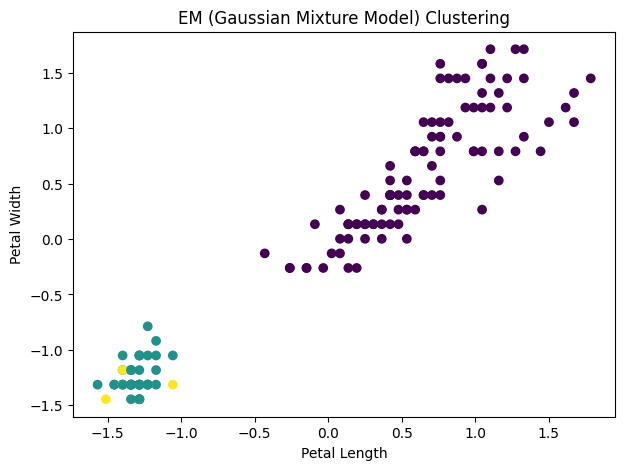

In [9]:
!pip install matplotlib
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))
plt.scatter(X_scaled[:,2], X_scaled[:,3], c=em_labels)
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("EM (Gaussian Mixture Model) Clustering")
plt.show()

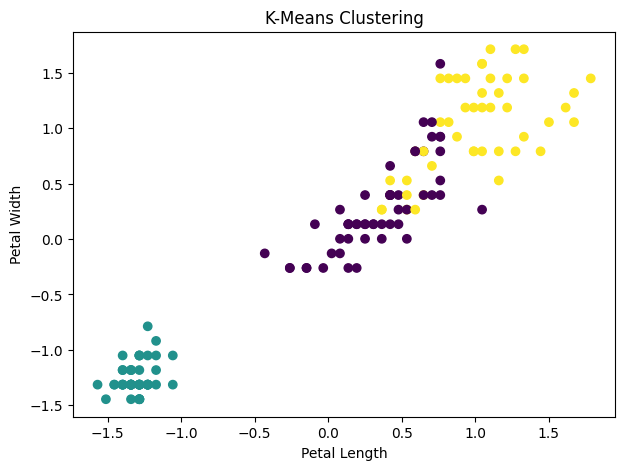

In [10]:
plt.figure(figsize=(7,5))
plt.scatter(X_scaled[:,2], X_scaled[:,3], c=kmeans_labels)
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("K-Means Clustering")
plt.show()

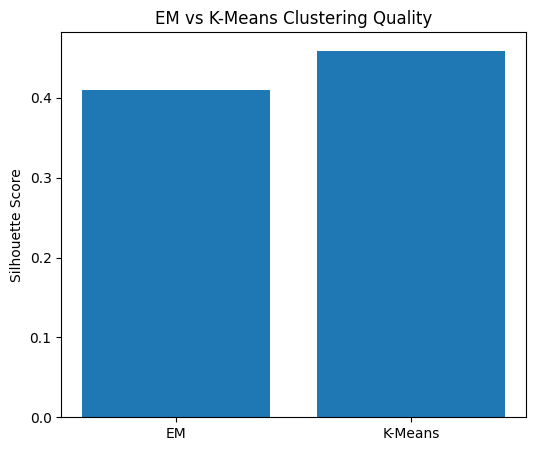

In [11]:
plt.figure(figsize=(6,5))
plt.bar(["EM", "K-Means"], [em_score, kmeans_score])
plt.ylabel("Silhouette Score")
plt.title("EM vs K-Means Clustering Quality")
plt.show()